# Assignment 4: Distributed Stream Processing (Kafka and Spark)

Kaziyev Nurassyl, BDA-2401. Synthetic AITU research-job events.

Before running: start a clean Kafka broker in a separate terminal with `.\start_kafka.ps1 -Reset`
(Kafka 4.3.2, one broker, KRaft mode, `localhost:9092`). Topics can not be deleted on Windows
(the broker crashes), so a clean run always starts from an empty broker.

The load tests of Part E are in `load_test.py`, because they start separate processes.

In [1]:
import csv
import io
import json
import os
import subprocess
import sys
import tempfile
import threading
import time
import urllib.request
import zipfile
import zlib
from collections import defaultdict
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from confluent_kafka import OFFSET_BEGINNING, Consumer, KafkaError, KafkaException, Producer, TopicPartition
from confluent_kafka.admin import AdminClient, NewTopic
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from load_test import BOOTSTRAP, JOB_TYPES, STATUSES, validate_event

TOPIC = "aitu.research.jobs"
DLQ_TOPIC = "aitu.research.jobs.dlq"
PARTITIONS = 3
REPLICATION = 1
CONSUMER_GROUP = "aitu-analytics"
EVENT_DATE = "2026-10-30"

OUT, FIG = Path("outputs"), Path("figures")
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

admin = AdminClient({"bootstrap.servers": BOOTSTRAP})
existing = admin.list_topics(timeout=10).topics
print("broker is up, topics:", sorted(t for t in existing if not t.startswith("__")))
if TOPIC in existing:
    probe = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": "probe"})
    stored = sum(probe.get_watermark_offsets(TopicPartition(TOPIC, p), timeout=10)[1]
                 for p in existing[TOPIC].partitions)
    probe.close()
    if stored:
        raise RuntimeError(f"{TOPIC} already has {stored} events, run .\\start_kafka.ps1 -Reset first")

broker is up, topics: ['aitu.research.jobs', 'aitu.research.jobs.dlq']


## Part A: Streaming architecture

Topic `aitu.research.jobs` with 3 partitions, key = `research_group`, so all events of one group
stay in order in one partition. Broken events go to `aitu.research.jobs.dlq`.
Broker config: Kafka's `server.properties` with `log.dirs=C:/Users/kazie/kafka/data` and
`auto.create.topics.enable=false` (otherwise a producer can create the topic with 1 partition).

In [2]:
def create_topic(name, partitions=PARTITIONS):
    existing = admin.list_topics(timeout=10).topics
    if name not in existing:
        admin.create_topics([NewTopic(name, num_partitions=partitions, replication_factor=REPLICATION,
                                      config={"retention.ms": str(7 * 24 * 3600 * 1000)})])[name].result()
    for _ in range(20):
        topics = admin.list_topics(timeout=10).topics
        if name in topics and len(topics[name].partitions) == partitions:
            break
        time.sleep(0.5)
    parts = topics[name].partitions
    print(f"{name}: partitions={len(parts)} leaders={[p.leader for p in parts.values()]} "
          f"replicas={[len(p.replicas) for p in parts.values()]}")


create_topic(TOPIC)
create_topic(DLQ_TOPIC, partitions=1)

expected_partition = {g: zlib.crc32(g.encode()) % PARTITIONS for g in ["G01", "G02", "G03"]}
print("expected partition per key:", expected_partition)

aitu.research.jobs: partitions=3 leaders=[1, 1, 1] replicas=[1, 1, 1]
aitu.research.jobs.dlq: partitions=1 leaders=[1] replicas=[1]
expected partition per key: {'G01': 2, 'G02': 1, 'G03': 0}


## Part B: Kafka producer and consumer

Three producers run at the same time, one per research group (like separate worker nodes),
with 1 s between events. The consumer runs at the same time in the group `aitu-analytics`:
it checks the schema, sends broken events to the DLQ, counts completed/failed jobs, average
duration by job_type, average CPU by group, and builds the 5-second windows of Part C.
Offsets are committed after each processed batch (at-least-once).

In [3]:
with open("data/research_events.csv", newline="") as f:
    events = [{"event_id": r["event_id"], "timestamp": f"{EVENT_DATE}T{r['timestamp']}",
               "research_group": r["research_group"], "job_type": r["job_type"],
               "duration_sec": int(r["duration_sec"]), "status": r["status"], "cpu_pct": int(r["cpu_pct"])}
              for r in csv.DictReader(f)]
pd.DataFrame(events)

,event_id,timestamp,research_group,job_type,duration_sec,status,cpu_pct
0,E001,2026-10-30T14:00:01,G01,ml,42,completed,61
1,E002,2026-10-30T14:00:02,G02,image,75,completed,74
2,E003,2026-10-30T14:00:03,G01,text,18,completed,38
3,E004,2026-10-30T14:00:04,G03,simulation,95,failed,92
4,E005,2026-10-30T14:00:05,G02,ml,51,completed,68
5,E006,2026-10-30T14:00:06,G01,image,88,completed,81
6,E007,2026-10-30T14:00:07,G03,ml,64,failed,89
7,E008,2026-10-30T14:00:08,G02,text,22,completed,44
8,E009,2026-10-30T14:00:09,G01,simulation,120,completed,94
9,E010,2026-10-30T14:00:10,G03,image,70,completed,78


In [4]:
def produce(topic, events, delay, log, name):
    producer = Producer({"bootstrap.servers": BOOTSTRAP, "client.id": name, "acks": "all",
                         "enable.idempotence": True, "linger.ms": 5})

    def on_delivery(err, msg):
        eid = json.loads(msg.value()).get("event_id")
        if err is not None:
            log.append(f"{name}: DELIVERY FAILED {eid}: {err}")
        else:
            log.append(f"{name}: sent {eid} key={msg.key().decode()} "
                       f"-> partition {msg.partition()} offset {msg.offset()}")

    for event in events:
        producer.produce(topic, key=event["research_group"], value=json.dumps(event), on_delivery=on_delivery)
        producer.poll(0)
        time.sleep(delay)
    left = producer.flush(10)
    log.append(f"{name}: done, {len(events)} events, not delivered: {left}")


def start_producers(topic, events, delay=1.0):
    log, threads = [], []
    for g in sorted({e["research_group"] for e in events}):
        group_events = [e for e in events if e["research_group"] == g]
        t = threading.Thread(target=produce, args=(topic, group_events, delay, log, f"producer-{g}"))
        t.start()
        threads.append(t)
    return threads, log

In [5]:
WINDOW = timedelta(seconds=5)
ALLOWED_LATENESS = timedelta(seconds=2)


def window_start(ts):
    midnight = datetime(ts.year, ts.month, ts.day)
    return midnight + timedelta(seconds=int((ts - midnight).total_seconds()) // 5 * 5)


class WindowAggregator:

    def __init__(self, watermark="partition"):
        self.mode = watermark
        self.open, self.closed, self.late = {}, [], []
        self.partition_max, self.partitions = {}, set()

    @property
    def watermark(self):
        if not self.partition_max:
            return None
        if self.mode == "global":
            return max(self.partition_max.values()) - ALLOWED_LATENESS
        if not self.partitions <= set(self.partition_max):
            return None
        return min(self.partition_max[p] for p in self.partitions) - ALLOWED_LATENESS

    def add(self, event, ts, partition):
        start = window_start(ts)
        if self.watermark is not None and start + WINDOW <= self.watermark:
            self.late.append(event["event_id"])
            return None
        w = self.open.setdefault(start, {"events": [], "failed": 0, "cpu_sum": 0})
        w["events"].append(event["event_id"])
        w["failed"] += event["status"] == "failed"
        w["cpu_sum"] += event["cpu_pct"]
        if ts > self.partition_max.get(partition, ts - WINDOW):
            self.partition_max[partition] = ts
        return start

    def close_ready(self, flush=False):
        done = []
        for start in sorted(self.open):
            if flush or (self.watermark is not None and start + WINDOW <= self.watermark):
                w = self.open.pop(start)
                n = len(w["events"])
                row = {"window": f"{start:%H:%M:%S}-{start + WINDOW:%H:%M:%S}",
                       "events": " ".join(sorted(w["events"])), "count": n, "failed": w["failed"],
                       "failure_rate_pct": round(100 * w["failed"] / n, 2),
                       "avg_cpu": round(w["cpu_sum"] / n, 2)}
                self.closed.append(row)
                done.append(row)
        return done

In [6]:
def run_consumer(topic, group_id, watermark="partition", idle_sec=5.0, max_wait=60):
    consumer = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": group_id,
                         "auto.offset.reset": "earliest", "enable.auto.commit": False})
    dlq = Producer({"bootstrap.servers": BOOTSTRAP})
    windows = WindowAggregator(watermark)
    assigned_at, log = [], []

    def on_assign(c, partitions):
        for p in partitions:
            p.offset = OFFSET_BEGINNING
        windows.partitions = {p.partition for p in partitions}
        assigned_at.append(time.time())
        log.append(f"assigned partitions: {sorted(windows.partitions)}")
        c.assign(partitions)

    consumer.subscribe([topic], on_assign=on_assign)
    status_count = defaultdict(lambda: {"completed": 0, "failed": 0})
    duration, cpu = defaultdict(list), defaultdict(list)
    valid = invalid = 0
    last_data, started = None, time.time()

    while time.time() - started < max_wait:
        batch = consumer.consume(num_messages=100, timeout=1.0)
        if not batch:
            if assigned_at and time.time() - (last_data or assigned_at[0]) > idle_sec:
                break
            continue
        last_data = time.time()
        for msg in batch:
            if msg.error():
                continue
            try:
                event = json.loads(msg.value())
                errors = validate_event(event)
            except json.JSONDecodeError as e:
                event, errors = None, [f"not JSON: {e}"]
            if errors:
                invalid += 1
                dlq.produce(DLQ_TOPIC, value=msg.value(), headers={"error": "; ".join(errors)})
                eid = event.get("event_id") if isinstance(event, dict) else "?"
                log.append(f"INVALID {eid} p{msg.partition()} off{msg.offset()} -> DLQ: {'; '.join(errors)}")
                continue
            valid += 1
            ts = datetime.fromisoformat(event["timestamp"])
            status_count[event["job_type"]][event["status"]] += 1
            duration[event["job_type"]].append(event["duration_sec"])
            cpu[event["research_group"]].append(event["cpu_pct"])
            start = windows.add(event, ts, msg.partition())
            wm = windows.watermark
            where = "LATE (dropped)" if start is None else f"window {start:%H:%M:%S}"
            log.append(f"recv {event['event_id']} p{msg.partition()} off{msg.offset()} event_time {ts:%H:%M:%S} "
                       f"-> {where}, watermark {'none yet' if wm is None else f'{wm:%H:%M:%S}'}")
            for row in windows.close_ready():
                log.append(f"  CLOSED window {row['window']}: {row['events']}")
        consumer.commit(asynchronous=True)

    for row in windows.close_ready(flush=True):
        log.append(f"  FLUSHED window {row['window']}: {row['events']}")
    try:
        consumer.commit(asynchronous=False)
    except KafkaException as e:
        if e.args[0].code() != KafkaError._NO_OFFSET:
            raise
    consumer.close()
    dlq.flush(5)
    return {"valid": valid, "invalid": invalid, "status_count": status_count, "duration": duration,
            "cpu": cpu, "windows": windows.closed, "late": windows.late, "log": log}

In [7]:
threads, producer_log = start_producers(TOPIC, events, delay=1.0)
result = run_consumer(TOPIC, CONSUMER_GROUP)
for t in threads:
    t.join()

print("\n".join(sorted(producer_log)))
print()
print("\n".join(result["log"]))
print(f"\nvalid events: {result['valid']}, invalid: {result['invalid']}, late: {result['late']}")

producer-G01: done, 4 events, not delivered: 0
producer-G01: sent E001 key=G01 -> partition 2 offset 0
producer-G01: sent E003 key=G01 -> partition 2 offset 1
producer-G01: sent E006 key=G01 -> partition 2 offset 2
producer-G01: sent E009 key=G01 -> partition 2 offset 3
producer-G02: done, 3 events, not delivered: 0
producer-G02: sent E002 key=G02 -> partition 1 offset 0
producer-G02: sent E005 key=G02 -> partition 1 offset 1
producer-G02: sent E008 key=G02 -> partition 1 offset 2
producer-G03: done, 3 events, not delivered: 0
producer-G03: sent E004 key=G03 -> partition 0 offset 0
producer-G03: sent E007 key=G03 -> partition 0 offset 1
producer-G03: sent E010 key=G03 -> partition 0 offset 2

assigned partitions: [0, 1, 2]
recv E001 p2 off0 event_time 14:00:01 -> window 14:00:00, watermark none yet
recv E003 p2 off1 event_time 14:00:03 -> window 14:00:00, watermark none yet
recv E006 p2 off2 event_time 14:00:06 -> window 14:00:05, watermark none yet
recv E009 p2 off3 event_time 14:00:0

In [8]:
actual_partition = {}
for line in producer_log:
    if " sent " in line:
        key = line.split("key=")[1].split()[0]
        actual_partition[key] = int(line.split("partition ")[1].split()[0])
print("expected:", expected_partition)
print("actual:  ", actual_partition)

expected: {'G01': 2, 'G02': 1, 'G03': 0}
actual:   {'G01': 2, 'G02': 1, 'G03': 0}


In [9]:
order = ["ml", "image", "text", "simulation"]
sc, du = result["status_count"], result["duration"]
part_b = pd.DataFrame([{"job_type": jt, "completed": sc[jt]["completed"], "failed": sc[jt]["failed"],
                        "avg_duration": round(sum(du[jt]) / len(du[jt]), 2)} for jt in order])
cpu_by_group = pd.DataFrame([{"research_group": g, "events": len(v), "avg_cpu": round(sum(v) / len(v), 2)}
                             for g, v in sorted(result["cpu"].items())])
part_b.to_csv(OUT / "partB_job_types.csv", index=False)
cpu_by_group.to_csv(OUT / "partB_cpu_by_group.csv", index=False)
print("completed:", part_b["completed"].sum(), " failed:", part_b["failed"].sum())
display(part_b)
display(cpu_by_group)

completed: 8  failed: 2


,job_type,completed,failed,avg_duration
0,ml,2,1,52.33
1,image,3,0,77.67
2,text,2,0,20.00
3,simulation,1,1,107.50


,research_group,events,avg_cpu
0,G01,4,68.50
1,G02,3,62.00
2,G03,3,86.33


### Monitoring: consumer lag

Lag = last offset in the partition minus the offset committed by the group. 0 means the group has processed everything.

In [10]:
def consumer_lag(topic, group_id):
    c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": group_id, "enable.auto.commit": False})
    parts = [TopicPartition(topic, p) for p in range(PARTITIONS)]
    rows = []
    for tp in c.committed(parts, timeout=10):
        low, high = c.get_watermark_offsets(tp, timeout=10)
        rows.append({"partition": tp.partition, "committed": tp.offset, "log_end": high,
                     "lag": high - tp.offset if tp.offset >= 0 else high})
    c.close()
    return pd.DataFrame(rows)


consumer_lag(TOPIC, CONSUMER_GROUP)

,partition,committed,log_end,lag
0,0,3,3,0
1,1,3,3,0
2,2,4,4,0


### Schema validation test

The same 10 events plus 3 broken events go to a separate test topic. The broken ones must go to the DLQ
and must not change the counts.

In [11]:
broken = [
    {"event_id": "X001", "timestamp": "2026-10-30T14:00:06", "research_group": "G02",
     "job_type": "audio", "duration_sec": 30, "status": "completed", "cpu_pct": 50},
    {"event_id": "X002", "timestamp": "2026-10-30T14:00:07", "research_group": "G01",
     "job_type": "ml", "duration_sec": 40, "status": "completed"},
    {"event_id": "X003", "timestamp": "2026-10-30T14:00:08", "research_group": "G03",
     "job_type": "text", "duration_sec": "fast", "status": "failed", "cpu_pct": 130},
]
VALIDATION_TOPIC = "aitu.research.jobs.validation-test"
create_topic(VALIDATION_TOPIC)
log = []
produce(VALIDATION_TOPIC, events + broken, 0, log, "validation-producer")
check = run_consumer(VALIDATION_TOPIC, "validation-test", idle_sec=4)
print("\n".join(line for line in check["log"] if line.startswith("INVALID")))
done = {s: sum(v[s] for v in check["status_count"].values()) for s in ("completed", "failed")}
print(f"valid: {check['valid']}, invalid sent to DLQ: {check['invalid']}, counts: {done}")

aitu.research.jobs.validation-test: partitions=3 leaders=[1, 1, 1] replicas=[1, 1, 1]


INVALID X002 p2 off4 -> DLQ: missing field cpu_pct
INVALID X001 p1 off3 -> DLQ: unknown job_type 'audio'
INVALID X003 p0 off3 -> DLQ: wrong type for duration_sec: str
valid: 10, invalid sent to DLQ: 3, counts: {'completed': 8, 'failed': 2}


## Part C: Windowed stream processing

5-second tumbling windows on event time, `[start, end)`: the event at 14:00:05 belongs to the second window.
Failure rate = failed / count, average CPU = CPU sum / count. A window is closed when the watermark passes its end,
the rest is flushed when the stream is idle.

In [12]:
part_c = pd.DataFrame(result["windows"])
part_c.to_csv(OUT / "partC_windows.csv", index=False)
part_c

,window,events,count,failed,failure_rate_pct,avg_cpu
0,14:00:00-14:00:05,E001 E002 E003 E004,4,1,25.0,66.25
1,14:00:05-14:00:10,E005 E006 E007 E008 E009,5,1,20.0,75.20
2,14:00:10-14:00:15,E010,1,0,0.0,78.00


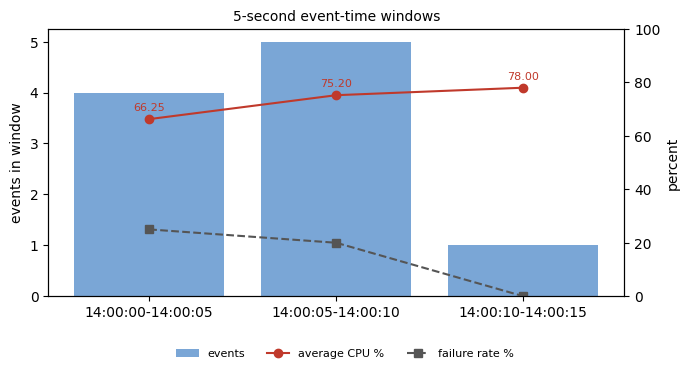

In [13]:
fig, ax1 = plt.subplots(figsize=(7, 3.7))
x = range(len(part_c))
ax1.bar(x, part_c["count"], color="#7aa6d6", label="events")
ax1.set_ylabel("events in window")
ax1.set_xticks(list(x), part_c["window"])
ax2 = ax1.twinx()
ax2.plot(x, part_c["avg_cpu"], "o-", color="#c0392b", label="average CPU %")
ax2.plot(x, part_c["failure_rate_pct"], "s--", color="#555555", label="failure rate %")
ax2.set_ylim(0, 100)
ax2.set_ylabel("percent")
for i, r in part_c.iterrows():
    ax2.annotate(f"{r['avg_cpu']:.2f}", (i, r["avg_cpu"]), textcoords="offset points",
                 xytext=(0, 6), ha="center", fontsize=8, color="#c0392b")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower center", ncol=3, frameon=False)
ax1.set_title("5-second event-time windows", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIG / "partC_windows.png", dpi=170)
plt.show()

### Experiment: global watermark against per-partition watermark

A new consumer reads the whole topic again (like a restart after a crash). Now all events are already in Kafka,
so the consumer gets them partition by partition, not in time order. My first version used one global watermark.

In [14]:
for mode in ["global", "partition"]:
    replay = run_consumer(TOPIC, f"replay-{mode}-{int(time.time())}", watermark=mode, idle_sec=4)
    arrival = [line.split()[1] + "(p" + line.split()[2][1:] + ")" for line in replay["log"] if line.startswith("recv")]
    print(f"{mode} watermark")
    print("  arrival order:", " ".join(arrival))
    print("  late (dropped):", replay["late"] or "none")
    print("  window counts:", [w["count"] for w in replay["windows"]])

global watermark
  arrival order: E001(p2) E003(p2) E006(p2) E009(p2) E002(p1) E005(p1) E008(p1) E004(p0) E007(p0) E010(p0)
  late (dropped): ['E002', 'E004']
  window counts: [2, 5, 1]


partition watermark
  arrival order: E001(p2) E003(p2) E006(p2) E009(p2) E002(p1) E005(p1) E008(p1) E004(p0) E007(p0) E010(p0)
  late (dropped): none
  window counts: [4, 5, 1]


## Part D: Spark Structured Streaming

The same topic is read by Spark (its own consumer group). Output: window, job_type, count, avg_duration.

Two Windows problems are solved here. The Kafka connector jars are put on the driver class path, because
`spark.jars.packages` calls chmod on the jars. And Hadoop needs `winutils.exe` for chmod, readlink and directory
listing, which is not installed, so a small Java class in `winfs/aitu/` skips these calls on the local disk.
It is compiled once with `javac`.

In [15]:
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType, StringType, StructField, StructType

MAVEN = "https://repo1.maven.org/maven2"
KAFKA_JARS = [
    "org/apache/spark/spark-sql-kafka-0-10_2.13/4.2.1/spark-sql-kafka-0-10_2.13-4.2.1.jar",
    "org/apache/spark/spark-token-provider-kafka-0-10_2.13/4.2.1/spark-token-provider-kafka-0-10_2.13-4.2.1.jar",
    "org/apache/kafka/kafka-clients/3.9.2/kafka-clients-3.9.2.jar",
    "org/apache/commons/commons-pool2/2.13.1/commons-pool2-2.13.1.jar",
]
JAR_DIR = Path.home() / ".spark-kafka-jars"


def windows_fs_jar():
    jar = JAR_DIR / "aitu-winfs.jar"
    if jar.exists():
        return str(jar)
    import pyspark
    hadoop_api = next((Path(pyspark.__file__).parent / "jars").glob("hadoop-client-api-*.jar"))
    build = Path(tempfile.mkdtemp(prefix="aitu_winfs_"))
    subprocess.run(["javac", "--release", "17", "-cp", str(hadoop_api), "-d", str(build),
                    *map(str, sorted(Path("winfs/aitu").glob("*.java")))], check=True)
    with zipfile.ZipFile(jar, "w") as z:
        for f in build.rglob("*.class"):
            z.write(f, f.relative_to(build).as_posix())
    return str(jar)


def class_path():
    JAR_DIR.mkdir(exist_ok=True)
    paths = []
    for rel in KAFKA_JARS:
        target = JAR_DIR / rel.rsplit("/", 1)[1]
        if not target.exists():
            urllib.request.urlretrieve(f"{MAVEN}/{rel}", target)
        paths.append(str(target))
    if os.name == "nt":
        paths.append(windows_fs_jar())
    return os.pathsep.join(paths)


builder = (SparkSession.builder.appName("aitu-research-job-windows").master("local[2]")
           .config("spark.driver.extraClassPath", class_path())
           .config("spark.sql.shuffle.partitions", "3")
           .config("spark.sql.session.timeZone", "UTC")
           .config("spark.ui.enabled", "false")
           .config("spark.ui.showConsoleProgress", "false"))
if os.name == "nt":
    builder = (builder.config("spark.hadoop.fs.file.impl", "aitu.NoPermLocalFileSystem")
                      .config("spark.hadoop.fs.AbstractFileSystem.file.impl", "aitu.NoPermLocalFs"))
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 4.2.1


In [16]:
EVENT_SCHEMA = StructType([
    StructField("event_id", StringType()),
    StructField("timestamp", StringType()),
    StructField("research_group", StringType()),
    StructField("job_type", StringType()),
    StructField("duration_sec", IntegerType()),
    StructField("status", StringType()),
    StructField("cpu_pct", IntegerType()),
])


def build_query(topic):
    raw = (spark.readStream.format("kafka")
           .option("kafka.bootstrap.servers", BOOTSTRAP)
           .option("subscribe", topic)
           .option("startingOffsets", "earliest")
           .load())
    parsed = (raw.select(F.from_json(F.col("value").cast("string"), EVENT_SCHEMA).alias("e"))
              .select("e.*")
              .withColumn("event_time", F.to_timestamp("timestamp"))
              .filter(F.col("event_id").isNotNull() & F.col("event_time").isNotNull()
                      & F.col("job_type").isin(*JOB_TYPES) & F.col("status").isin(*STATUSES)
                      & (F.col("duration_sec") > 0) & F.col("cpu_pct").between(0, 100)))
    return (parsed.groupBy(F.window("event_time", "5 seconds"), F.col("job_type"))
            .agg(F.count("*").alias("count"), F.round(F.avg("duration_sec"), 2).alias("avg_duration")))


spark_result = build_query(TOPIC)
schema_text = spark_result._jdf.schema().treeString()
(OUT / "partD_spark_schema.txt").write_text(schema_text)
print(schema_text)

root
 |-- window: struct (nullable = false)
 |    |-- start: timestamp (nullable = true)
 |    |-- end: timestamp (nullable = true)
 |-- job_type: string (nullable = true)
 |-- count: long (nullable = false)
 |-- avg_duration: double (nullable = true)



In [17]:
batches = []


def save_batch(batch_df, batch_id):
    pdf = (batch_df.select(F.date_format("window.start", "HH:mm:ss").alias("window_start"),
                           F.date_format("window.end", "HH:mm:ss").alias("window_end"),
                           "job_type", "count", "avg_duration")
           .orderBy("window_start", "job_type").toPandas())
    batches.append((batch_id, pdf))


def start_query(df, trigger):
    return (df.writeStream.outputMode("complete").foreachBatch(save_batch)
            .option("checkpointLocation", tempfile.mkdtemp(prefix="aitu_spark_ckpt_"))
            .trigger(**trigger).start())


query = start_query(spark_result, {"availableNow": True})
query.awaitTermination()
part_d = batches[-1][1]
part_d.to_csv(OUT / "partD_spark_output.csv", index=False)
p = query.lastProgress
print(f"micro-batch {p['batchId']}: input rows {p['numInputRows']}, "
      f"trigger time {p['durationMs']['triggerExecution']} ms (addBatch {p['durationMs']['addBatch']} ms)")
part_d

micro-batch 0: input rows 10, trigger time 4959 ms (addBatch 3675 ms)


,window_start,window_end,job_type,count,avg_duration
0,14:00:00,14:00:05,image,1,75.0
1,14:00:00,14:00:05,ml,1,42.0
2,14:00:00,14:00:05,simulation,1,95.0
3,14:00:00,14:00:05,text,1,18.0
4,14:00:05,14:00:10,image,1,88.0
5,14:00:05,14:00:10,ml,2,57.5
6,14:00:05,14:00:10,simulation,1,120.0
7,14:00:05,14:00:10,text,1,22.0
8,14:00:10,14:00:15,image,1,70.0


### Live run

Spark runs with a 2 s trigger while the three producers send the events (1.5 s apart) to a new topic,
so the result grows from micro-batch to micro-batch.

In [18]:
LIVE_TOPIC = "aitu.research.jobs.live"
create_topic(LIVE_TOPIC)
batches.clear()
live_query = start_query(build_query(LIVE_TOPIC), {"processingTime": "2 seconds"})
time.sleep(10)
threads, live_log = start_producers(LIVE_TOPIC, events, delay=1.5)
for t in threads:
    t.join()
time.sleep(25)
live_query.stop()
for batch_id, pdf in batches:
    print(f"micro-batch {batch_id}: {len(pdf)} rows, count per window "
          f"{pdf.groupby('window_start')['count'].sum().to_dict()}")

aitu.research.jobs.live: partitions=3 leaders=[1, 1, 1] replicas=[1, 1, 1]


micro-batch 0: 0 rows, count per window {}
micro-batch 1: 3 rows, count per window {'14:00:00': 3}
micro-batch 2: 8 rows, count per window {'14:00:00': 4, '14:00:05': 4, '14:00:10': 1}
micro-batch 3: 9 rows, count per window {'14:00:00': 4, '14:00:05': 5, '14:00:10': 1}


In [19]:
spark.stop()

## Part E: Throughput and latency

Run by `load_test.py` (producer and consumer in separate processes, 20 s per rate, a new 3-partition topic
for each run). CPU % is process CPU time / wall time (100 % = one core), system CPU is the whole machine.
Baseline consumer settings are the same as in Part B: batch of 100, batch timeout 1 s, commit per batch.

The results below were measured on 30/10/2026 (6 cores / 12 threads, 15.2 GB RAM). Set `RUN_LOAD_TESTS = True`
to measure again (about 6 minutes, the new rows are added to the CSV).

In [20]:
RUN_LOAD_TESTS = False

commands = [
    "--rates 10 100 500 --duration 20",
    "--rates 10 100 500 --duration 20 --batch-timeout 0.05",
    "--rates 0 --max-events 50000",
    "--rates 0 --max-events 50000 --batch-timeout 0.05",
    "--rates 500 0 --duration 20 --max-events 20000 --batch-size 1 --batch-timeout 0.05 --commit message",
    "--scaling --events 200000 --consumers 1 2 3",
]
if RUN_LOAD_TESTS:
    for args in commands:
        print(">>> python load_test.py", args)
        subprocess.run([sys.executable, "load_test.py", *args.split()], check=True)

load = pd.read_csv(OUT / "partE_load_results.csv")
cols = ["input_rate", "batch_timeout_s", "commit", "events", "received", "observed_throughput",
        "avg_latency_ms", "p50_latency_ms", "p95_latency_ms", "consumer_cpu_pct", "producer_cpu_pct", "system_cpu_pct"]
load[cols]

,input_rate,batch_timeout_s,commit,events,received,observed_throughput,avg_latency_ms,p50_latency_ms,p95_latency_ms,consumer_cpu_pct,producer_cpu_pct,system_cpu_pct
0,10,1.00,batch,200,200,10.4,536.63,538.05,994.63,0.8,0.5,10.8
1,100,1.00,batch,2000,2000,100.1,507.19,504.10,953.55,2.1,6.6,13.1
2,500,1.00,batch,10000,10000,513.4,110.50,107.61,198.70,6.1,14.3,16.0
3,10,0.05,batch,200,200,10.3,59.33,52.85,80.95,1.0,2.0,11.0
4,100,0.05,batch,2000,2000,102.8,40.55,32.24,67.16,2.6,5.5,10.6
5,500,0.05,batch,10000,10000,511.9,39.92,33.82,61.57,8.2,14.1,17.3
6,max,1.00,batch,50000,50000,61600.7,579.64,610.26,703.47,113.6,142.7,20.6
7,max,0.05,batch,50000,50000,63218.0,519.38,543.83,627.52,114.6,143.0,26.5
8,500,0.05,message,10000,10000,513.3,18.93,6.90,27.91,23.4,15.5,14.1
9,max,0.05,message,20000,20000,1466.3,7256.33,7332.47,13266.10,50.3,67.1,15.0


In [21]:
pd.read_csv(OUT / "partE_scaling_results.csv")

,consumers,events,drain_sec,throughput_eps,per_consumer_events,partitions,avg_consumer_cpu_pct
0,1,200000,3.03,66046,200000,"[0, 1, 2]",104.7
1,2,200000,2.64,75879,166870 33130,"[0, 1] [2]",65.5
2,3,200000,1.80,111357,66869 100001 33130,[1] [0] [2],73.1


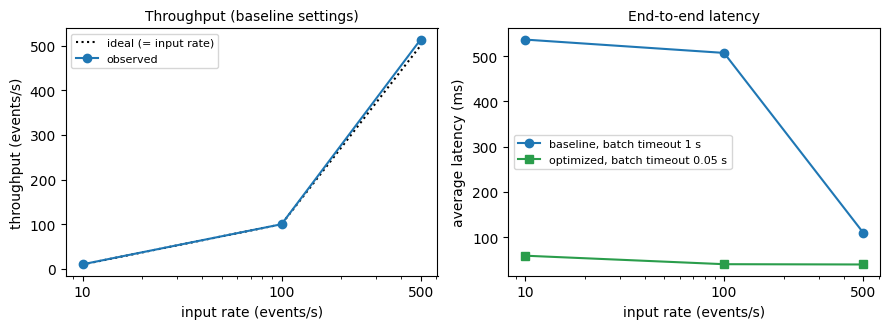

In [22]:
df = load[(load["commit"] == "batch") & (load["input_rate"] != "max")]
df = df.assign(rate=df["input_rate"].astype(int)).sort_values("rate")
base, opt = df[df["batch_timeout_s"] == 1.0], df[df["batch_timeout_s"] == 0.05]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
a1.plot(base["rate"], base["rate"], "k:", label="ideal (= input rate)")
a1.plot(base["rate"], base["observed_throughput"], "o-", label="observed")
a1.set_ylabel("throughput (events/s)")
a1.set_title("Throughput (baseline settings)", fontsize=10)
a2.plot(base["rate"], base["avg_latency_ms"], "o-", label="baseline, batch timeout 1 s")
a2.plot(opt["rate"], opt["avg_latency_ms"], "s-", color="#2a9d4b", label="optimized, batch timeout 0.05 s")
a2.set_ylabel("average latency (ms)")
a2.set_title("End-to-end latency", fontsize=10)
for a in (a1, a2):
    a.set_xscale("log")
    a.set_xticks([10, 100, 500], ["10", "100", "500"])
    a.set_xlabel("input rate (events/s)")
    a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "partE_load.png", dpi=170)
plt.show()

Latency is about 0.5 s at 10 and 100 events/s because `consume(100, timeout=1.0)` waits until 100 messages arrive
or 1 s passes. At 500 events/s the batch fills in 0.2 s. With a 0.05 s timeout the latency is about 40 ms at the
same CPU. One consumer reaches about 61,600 events/s (CPU bound). Three consumers are only 1.69 times faster
than one, because the group keys are spread unevenly over the 3 partitions.

## Architecture diagram (Part A)

Drawn at the end, because it uses the real partition of each key from the delivery reports in Part B.

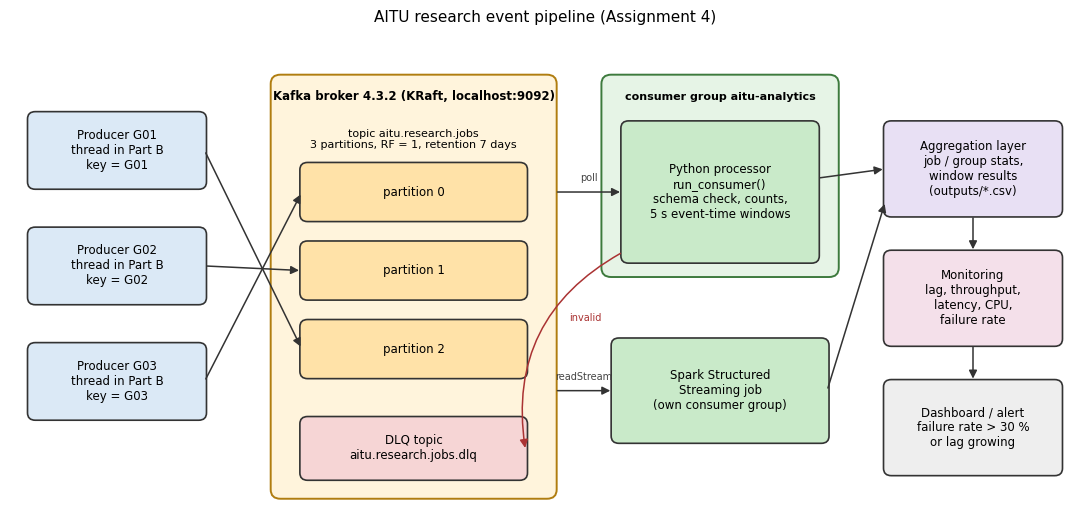

In [23]:
def box(ax, x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8.5)


def arrow(ax, x1, y1, x2, y2, text=None):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, lw=1.1, color="#333333"))
    if text:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, text, ha="center", fontsize=7, color="#444444")


fig, ax = plt.subplots(figsize=(11, 5.4))
ax.set_xlim(0, 11)
ax.set_ylim(0.3, 5.6)
ax.axis("off")
part_y = {0: 3.55, 1: 2.7, 2: 1.85}
groups = ["G01", "G02", "G03"]
for i, g in enumerate(groups):
    box(ax, 0.2, 3.9 - i * 1.25, 1.8, 0.8, f"Producer {g}\nthread in Part B\nkey = {g}", "#dbe9f6")

ax.add_patch(FancyBboxPatch((2.7, 0.55), 2.9, 4.55, boxstyle="round,pad=0.02,rounding_size=0.1",
                            fc="#fff4dc", ec="#b07d10", lw=1.4))
ax.text(4.15, 4.85, "Kafka broker 4.3.2 (KRaft, localhost:9092)", ha="center", fontsize=8.5, weight="bold")
ax.text(4.15, 4.42, f"topic {TOPIC}\n3 partitions, RF = 1, retention 7 days", ha="center", fontsize=8, va="center")
for pnum, y in part_y.items():
    box(ax, 3.0, y, 2.3, 0.6, f"partition {pnum}", "#ffe2a8")
box(ax, 3.0, 0.75, 2.3, 0.65, f"DLQ topic\n{DLQ_TOPIC}", "#f6d5d5")
for i, g in enumerate(groups):
    arrow(ax, 2.0, 4.3 - i * 1.25, 3.0, part_y[actual_partition[g]] + 0.3)

ax.add_patch(FancyBboxPatch((6.1, 2.95), 2.4, 2.15, boxstyle="round,pad=0.02,rounding_size=0.1",
                            fc="#e6f4e6", ec="#3d7a3d", lw=1.4))
ax.text(7.3, 4.85, f"consumer group {CONSUMER_GROUP}", ha="center", fontsize=8, weight="bold")
box(ax, 6.3, 3.1, 2.0, 1.5, "Python processor\nrun_consumer()\nschema check, counts,\n5 s event-time windows", "#c9eac9")
box(ax, 6.2, 1.15, 2.2, 1.1, "Spark Structured\nStreaming job\n(own consumer group)", "#c9eac9")
arrow(ax, 5.6, 3.85, 6.3, 3.85, "poll")
arrow(ax, 5.6, 1.7, 6.2, 1.7, "readStream")
ax.add_patch(FancyArrowPatch((6.3, 3.2), (5.3, 1.05), arrowstyle="-|>", mutation_scale=12, lw=1.1,
                             color="#a33", connectionstyle="arc3,rad=0.35"))
ax.text(5.75, 2.45, "invalid", fontsize=7, color="#a33")

box(ax, 9.0, 3.6, 1.8, 1.0, "Aggregation layer\njob / group stats,\nwindow results\n(outputs/*.csv)", "#e8e0f4")
box(ax, 9.0, 2.2, 1.8, 1.0, "Monitoring\nlag, throughput,\nlatency, CPU,\nfailure rate", "#f4e0ea")
box(ax, 9.0, 0.8, 1.8, 1.0, "Dashboard / alert\nfailure rate > 30 %\nor lag growing", "#eeeeee")
arrow(ax, 8.3, 4.0, 9.0, 4.1)
arrow(ax, 8.4, 1.7, 9.0, 3.75)
arrow(ax, 9.9, 3.6, 9.9, 3.2)
arrow(ax, 9.9, 2.2, 9.9, 1.8)
ax.set_title("AITU research event pipeline (Assignment 4)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "partA_architecture.png", dpi=170)
plt.show()